# Wave spectrum and wave periods (question 3)

**Assignment:** *Plot a (variance density) spectrum that has the value of $H_s$ given in the table. Choose a suitable spectral shape and peak period for locally generated (and thus steep) wind waves. You can assume long-crested waves.*
- *a. Determine $T_m$, $T_{m-10}$ and $T_{m01}$.*
- *b. Calculate the wave steepness.*

**Given:** water depth $h = 25$ m, significant wave height $H_s = 7$ m, $g = 9.81$ m/s².

**Approach:** an assumed steepness gives the wave number. The dispersion relation then gives the peak period. With $H_s$ and $T_p$ known, a JONSWAP spectrum is constructed, and its spectral moments give the mean periods and the steepness.

In [1]:
#Import the necessary packages
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid


#Define the given parameters (assignment)
H_DEPTH = 25.0  #water depth h [m]
HS      = 7.0   #significant wave height [m]
G       = 9.81  #gravitational acceleration [m/s2]


#Define the assumed parameters
KA      = 0.25                  #wave steepness ka [-]
GAMMA   = 3.3                   #JONSWAP peak enhancement factor [-]
SIGMA_A, SIGMA_B = 0.07, 0.09   #JONSWAP peak width for f <= fp and f > fp [-]


#Define the folder where the figures are saved (next to this notebook)
OUT_DIR = Path(".")


#Create the plot style
def style(ax, title):
    ax.set_title(title)
    ax.grid(True, color="0.88", lw=0.6)

    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


#Define a function for the angular frequency from the full dispersion relation (valid for all depths): w^2 = g k tanh(kh)
def omega_full(k, h=H_DEPTH):
    return np.sqrt(G * k * np.tanh(k * h))


#Define a function for the angular frequency from the deep-water approximation: w^2 = g k
def omega_deep(k):
    return np.sqrt(G * k)


#Define a function that classifies the depth regime from kh
def regime(kh):
    if kh > np.pi:
        return "deep water"
    if kh < np.pi / 10:
        return "shallow water"
    return "intermediate depth"


#Define a function for the Pierson-Moskowitz spectrum, written in Hs and fp
def E_pm(f, hs, fp):
    return 5 / 16 * hs**2 * fp**4 * f**-5 * np.exp(-5 / 4 * (fp / f)**4) #[m2/Hz]


#Define a function for the JONSWAP spectrum: PM shape x peak enhancement, normalised with A_gamma
def E_jonswap(f, hs, fp, gamma=GAMMA, sa=SIGMA_A, sb=SIGMA_B):
    a_gamma = 1 - 0.287 * np.log(gamma)
    sigma = np.where(f <= fp, sa, sb)
    peak = gamma ** np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))
    return a_gamma * E_pm(f, hs, fp) * peak #[m2/Hz]

## Step 1 — Assumed steepness

The waves are locally generated, so they are **steep, but not breaking**. We assume

$$ka = 0.25,$$

which lies within the range 0.1–0.3 mentioned in the lecture and well below the breaking limit $ka \approx 0.44$ (L3 slide 9). The amplitude follows from the significant wave height:

$$a = \frac{H_s}{2} = 3.5\ \text{m}.$$

In [2]:
#Calculate the amplitude from the significant wave height
a = HS / 2 #[m]


#Print the results
print(f"ka = {KA}  (assumption)")
print(f"a  = Hs/2 = {a:.2f} m")

ka = 0.25  (assumption)
a  = Hs/2 = 3.50 m


## Step 2 — Wave number and wave length

From the assumed steepness and amplitude:

$$k = \frac{ka}{a}, \qquad \lambda = \frac{2\pi}{k}.$$

In [3]:
#Calculate the wave number and the wave length
k   = KA / a          #[rad/m]
lam = 2 * np.pi / k   #[m]


#Print the results
print(f"k      = {k:.4f} rad/m")
print(f"lambda = {lam:.1f} m")

k      = 0.0714 rad/m
lambda = 88.0 m


## Step 3 — Depth regime

The ratio $kh$ determines the depth regime (L3 slide 15):

$$\text{deep: } kh > \pi, \qquad \text{shallow: } kh < \frac{\pi}{10}, \qquad \text{otherwise intermediate.}$$

In [4]:
#Calculate kh to determine the depth regime
kh = k * H_DEPTH #[-]


#Print the results
print(f"kh = {kh:.3f}   (pi/10 = {np.pi/10:.3f}, pi = {np.pi:.3f})")
print(f"-> {regime(kh)}")

kh = 1.786   (pi/10 = 0.314, pi = 3.142)
-> intermediate depth


## Step 4 — Angular frequency and peak period

The angular frequency follows from the **full dispersion relation** (L3 slide 14), which is valid for all depths:

$$\omega = \sqrt{g k \tanh(kh)}, \qquad T = \frac{2\pi}{\omega}.$$

This period is used as the **peak period** of the spectrum: $T_p = T$, $f_p = 1/T_p$.

For comparison, the deep-water approximation $\omega^2 = gk$ is also computed. The deep-water wave length belonging to $T_p$,

$$\lambda_0 = \frac{g T_p^2}{2\pi},$$

is needed for the steepness in part b.

In [5]:
#Calculate the angular frequency, peak period and peak frequency with the full dispersion relation
omega = omega_full(k)     #[rad/s]
Tp    = 2 * np.pi / omega #[s]
fp    = 1 / Tp            #[Hz]


#Calculate the same with the deep-water approximation for comparison
omega0 = omega_deep(k)       #[rad/s]
T_deep = 2 * np.pi / omega0  #[s]


#Calculate the deep-water wave length belonging to Tp
lam0 = G * Tp**2 / (2 * np.pi) #[m]


#Print the results
print(f"Full dispersion relation : omega = {omega:.4f} rad/s,  Tp = {Tp:.2f} s,  fp = {fp:.4f} Hz")
print(f"Deep-water approximation : omega = {omega0:.4f} rad/s,  T  = {T_deep:.2f} s  "
      f"({100 * (T_deep / Tp - 1):+.1f} % vs full)")
print(f"Deep-water wave length   : lambda0 = g Tp^2 / 2pi = {lam0:.1f} m   "
      f"(local lambda = {lam:.1f} m, ratio lambda/lambda0 = {lam / lam0:.3f})")

Full dispersion relation : omega = 0.8139 rad/s,  Tp = 7.72 s,  fp = 0.1295 Hz
Deep-water approximation : omega = 0.8371 rad/s,  T  = 7.51 s  (-2.8 % vs full)
Deep-water wave length   : lambda0 = g Tp^2 / 2pi = 93.1 m   (local lambda = 88.0 m, ratio lambda/lambda0 = 0.945)


## Step 5 — Choice of spectrum

The choice between Pierson–Moskowitz (PM) and JONSWAP depends on the **state of development of the sea**, not on the water depth. Both are deep-water spectra.
- **PM:** a fully developed sea (unlimited fetch and duration).
- **JONSWAP:** a **fetch-limited**, still growing sea, with a sharper and higher peak.

The waves here are *locally generated*, i.e. fetch-limited, so **JONSWAP** is chosen. Standard values are $\gamma = 3.3$, $\sigma = 0.07$ for $f \le f_p$ and $\sigma = 0.09$ for $f > f_p$, with normalisation $A_\gamma = 1 - 0.287\ln\gamma$ (L5 slide 12):

$$E_{PM}(f) = \frac{5}{16} H_s^2 f_p^4 f^{-5} \exp\!\left[-\frac{5}{4}\left(\frac{f_p}{f}\right)^4\right]$$

$$E(f) = A_\gamma\, E_{PM}(f)\; \gamma^{\exp\left[-\frac{(f - f_p)^2}{2\sigma^2 f_p^2}\right]}$$

**Notes**
- Step 3 shows that $kh$ is in the **intermediate** regime. Using a deep-water spectrum is therefore a simplification.
- The waves are **long-crested**, so a 1D spectrum $E(f)$ is used, without directional spreading.

In [6]:
#Calculate the JONSWAP normalisation factor A_gamma
a_gamma = 1 - 0.287 * np.log(GAMMA) #[-]


#Print the results
print(f"gamma = {GAMMA},  sigma = {SIGMA_A} / {SIGMA_B},  A_gamma = {a_gamma:.4f}")

gamma = 3.3,  sigma = 0.07 / 0.09,  A_gamma = 0.6573


## Step 6 — Plot of the spectrum

JONSWAP and PM spectra with the same $H_s$ and $T_p$, plotted in one figure. The figure is also saved as a PNG in this folder.

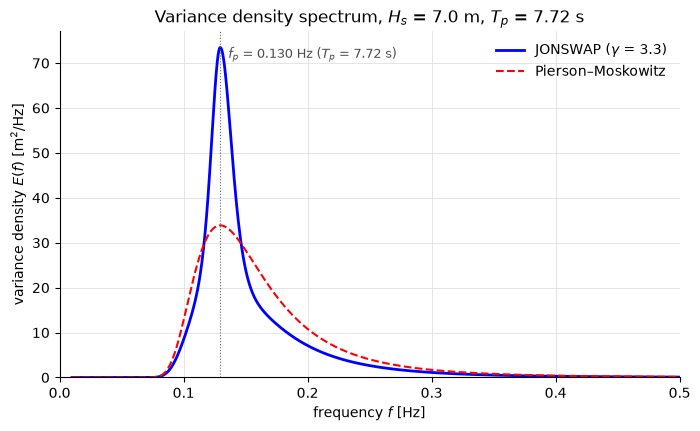

Saved: wave_spectrum_JONSWAP_PM.png


In [7]:
#Create the frequency range and calculate the JONSWAP and PM spectra
f_plot = np.linspace(0.01, 0.5, 2000)   #[Hz]
E_j    = E_jonswap(f_plot, HS, fp)      #[m2/Hz]
E_p    = E_pm(f_plot, HS, fp)           #[m2/Hz]


#Plot both spectra with the peak frequency marked
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f_plot, E_j, "-", color='b', lw=2, label=rf"JONSWAP ($\gamma$ = {GAMMA})")
ax.plot(f_plot, E_p, "--", color='r', lw=1.5, label="Pierson–Moskowitz")
ax.axvline(fp, color="0.4", lw=0.8, ls=":")
ax.text(fp, ax.get_ylim()[1] * 0.95, rf"  $f_p$ = {fp:.3f} Hz ($T_p$ = {Tp:.2f} s)", va="top", fontsize=9, color="0.3")

ax.set_xlabel(r"frequency $f$ [Hz]")
ax.set_ylabel(r"variance density $E(f)$ [m$^2$/Hz]")
ax.set_xlim(0, 0.5)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
style(ax, rf"Variance density spectrum, $H_s$ = {HS} m, $T_p$ = {Tp:.2f} s")
plt.savefig(OUT_DIR / "wave_spectrum_JONSWAP_PM.png", dpi=300, bbox_inches="tight")
plt.show()


#Print the results
print("Saved: wave_spectrum_JONSWAP_PM.png")

## Step 7 — Part a: spectral moments and mean periods

The spectral moments are computed numerically on a fine frequency grid ($f$ = 0.01–1.0 Hz, $\Delta f$ = 0.0005 Hz):

$$m_n = \int f^n E(f)\, df, \qquad n = -1, 0, 1, 2.$$

The grid does not start at $f = 0$, because of the $f^{-1}$ in $m_{-1}$.

From these moments follow:

$$H_{m0} = 4\sqrt{m_0}\ (\text{check} \approx H_s), \qquad T_{m01} = \frac{m_0}{m_1}, \qquad T_m = T_{m02} = \sqrt{\frac{m_0}{m_2}}, \qquad T_{m-10} = \frac{m_{-1}}{m_0}.$$

In [8]:
#Define a function that calculates the spectral moments m_-1, m_0, m_1 and m_2 of the JONSWAP spectrum
DF = 0.0005 #frequency step [Hz]

def moments(fmax, fmin=0.01, df=DF):
    f = np.arange(fmin, fmax + df / 2, df)
    E = E_jonswap(f, HS, fp)
    return {n: trapezoid(f**n * E, f) for n in (-1, 0, 1, 2)}


#Calculate the spectral moments up to 1.0 Hz
m = moments(1.0)


#Calculate the significant wave height (check) and the mean periods
Hm0   = 4 * np.sqrt(m[0])      #[m]
Tm01  = m[0] / m[1]            #[s]
Tm02  = np.sqrt(m[0] / m[2])   #[s]
Tm_10 = m[-1] / m[0]           #[s]


#Print the results
print(f"m-1 = {m[-1]:.4f} m2 s,  m0 = {m[0]:.4f} m2,  m1 = {m[1]:.5f} m2/s,  m2 = {m[2]:.6f} m2/s2")
print(f"Hm0 = 4 sqrt(m0)   = {Hm0:.3f} m   (check: Hs = {HS} m)")
print(f"Tm01  = m0/m1      = {Tm01:.2f} s")
print(f"Tm02  = sqrt(m0/m2)= {Tm02:.2f} s   (= Tm)")
print(f"Tm-10 = m-1/m0    = {Tm_10:.2f} s")
print(f"Tp                 = {Tp:.2f} s")
print("Order Tm02 < Tm01 < Tm-10 < Tp:", Tm02 < Tm01 < Tm_10 < Tp)

m-1 = 21.4075 m2 s,  m0 = 3.0692 m2,  m1 = 0.47567 m2/s,  m2 = 0.083813 m2/s2
Hm0 = 4 sqrt(m0)   = 7.008 m   (check: Hs = 7.0 m)
Tm01  = m0/m1      = 6.45 s
Tm02  = sqrt(m0/m2)= 6.05 s   (= Tm)
Tm-10 = m-1/m0    = 6.97 s
Tp                 = 7.72 s
Order Tm02 < Tm01 < Tm-10 < Tp: True


**Sensitivity to the upper integration limit.** Higher moments give more weight to high frequencies, so $m_2$ (and therefore $T_{m02}$) depends on where the integration stops. The $f^{-5}$ tail of the spectrum decays slowly. The table compares $f_{max}$ = 0.5, 1.0 and 2.0 Hz.

In [9]:
#Calculate the significant wave height and mean periods for different upper integration limits
rows = []
for fmax in (0.5, 1.0, 2.0):
    mm = moments(fmax)
    rows.append({"f_max [Hz]": fmax, "Hm0 [m]": 4 * np.sqrt(mm[0]), "Tm-10 [s]": mm[-1] / mm[0],
                 "Tm01 [s]": mm[0] / mm[1], "Tm02 [s]": np.sqrt(mm[0] / mm[2])})


#Create a panda with all values and print it out
pd.DataFrame(rows).style.hide(axis="index").format(precision=3)

f_max [Hz],Hm0 [m],Tm-10 [s],Tm01 [s],Tm02 [s]
0.500,6.996,6.993,6.521,6.200
1.000,7.008,6.975,6.452,6.051
2.000,7.008,6.974,6.443,6.014


## Step 8 — Part b: wave steepness

The wave steepness is computed in three ways:

$$s_{op} = \frac{H_s}{\lambda_{0,p}} = \frac{2\pi H_s}{g T_p^2}, \qquad s_{m-10} = \frac{H_s}{\lambda_{0}(T_{m-10})} = \frac{2\pi H_s}{g T_{m-10}^2}, \qquad s_{local} = \frac{H_s}{\lambda}.$$

Here $\lambda$ is the local wave length from the dispersion relation at $h = 25$ m. These values are compared with the assumed $ka = 0.25$, which corresponds to $s = H/\lambda = 2a\,k/2\pi = ka/\pi \approx 0.08$, and with the typical $ka$ values from L3 slide 9.

In [10]:
#Calculate the deep-water wave lengths belonging to Tp and Tm-10
lam0_p   = G * Tp**2 / (2 * np.pi)      #[m]
lam0_m10 = G * Tm_10**2 / (2 * np.pi)   #[m]


#Calculate the wave steepness in three ways and the steepness belonging to the assumed ka
s_op      = HS / lam0_p     #[-]
s_m10     = HS / lam0_m10   #[-]
s_local   = HS / lam        #[-]
s_assumed = KA / np.pi      #[-]


#Print the results
print(f"s_op     = Hs / lambda0(Tp)      = {HS} / {lam0_p:.1f}   = {s_op:.4f}   (ka-equivalent {np.pi * s_op:.3f})")
print(f"s_m-10  = Hs / lambda0(Tm-10)  = {HS} / {lam0_m10:.1f}   = {s_m10:.4f}   (ka-equivalent {np.pi * s_m10:.3f})")
print(f"s_local  = Hs / lambda (h = 25 m) = {HS} / {lam:.1f}   = {s_local:.4f}   (ka-equivalent {np.pi * s_local:.3f})")
print(f"assumed  : ka = {KA}  ->  s = ka/pi = {s_assumed:.4f}")


#Print the typical ka values for comparison
print("\nTypical ka values (L3 slide 9):")
for name, rng in [("swell", "0.02–0.05"), ("wind sea", "0.05–0.1"), ("storm", "0.1–0.15"), ("breaking", "≈ 0.44")]:
    print(f"  {name:9s} {rng}")

s_op     = Hs / lambda0(Tp)      = 7.0 / 93.1   = 0.0752   (ka-equivalent 0.236)
s_m-10  = Hs / lambda0(Tm-10)  = 7.0 / 76.0   = 0.0922   (ka-equivalent 0.290)
s_local  = Hs / lambda (h = 25 m) = 7.0 / 88.0   = 0.0796   (ka-equivalent 0.250)
assumed  : ka = 0.25  ->  s = ka/pi = 0.0796

Typical ka values (L3 slide 9):
  swell     0.02–0.05
  wind sea  0.05–0.1
  storm     0.1–0.15
  breaking  ≈ 0.44


**Interpretation.**
- $s_{local}$ is exactly the assumed steepness: $\lambda$ was derived from $ka$ in Step 2, so this value simply **feeds back the assumption** from Step 1.
- $s_{op} \approx 0.075$ is slightly **lower** than $s_{local}$, because the deep-water wave length is longer than the local one ($\lambda_0 = 93$ m vs $\lambda = 88$ m at $h = 25$ m). $s_{m-10} \approx 0.092$ is **higher**, because $T_{m-10} < T_p$ gives a shorter deep-water wave length (76 m).
- Compared with the typical values, $ka = 0.25$ is **steeper than a storm sea** (0.1–0.15) but clearly below breaking (≈ 0.44). That is consistent with steep, locally generated wind waves, but it is at the upper end. A smaller $ka$ would give a longer $T_p$ and a lower steepness.

## Step 9 — Summary

In [11]:
#Collect all results in one table
summary = pd.DataFrame([
    ("ka (assumed)",             KA,         "-"),
    ("a = Hs/2",                 a,          "m"),
    ("k",                        k,          "rad/m"),
    ("lambda (local, h = 25 m)", lam,        "m"),
    ("kh",                       kh,         "-"),
    ("regime",                   regime(kh), ""),
    ("omega",                    omega,      "rad/s"),
    ("Tp",                       Tp,         "s"),
    ("fp",                       fp,         "Hz"),
    ("lambda0 = g Tp^2 / 2pi",   lam0,       "m"),
    ("Hm0 = 4 sqrt(m0) (check)", Hm0,        "m"),
    ("Tm01",                     Tm01,       "s"),
    ("Tm02 = Tm",                Tm02,       "s"),
    ("Tm-10",                    Tm_10,      "s"),
    ("s_op",                     s_op,       "-"),
    ("s_m-10",                   s_m10,      "-"),
], columns=["quantity", "value", "unit"])


#Round the values and print the table
summary["value"] = [f"{v:.4g}" if isinstance(v, float) else v for v in summary["value"]]
summary.style.hide(axis="index")

quantity,value,unit
ka (assumed),0.25,-
a = Hs/2,3.5,m
k,0.07143,rad/m
"lambda (local, h = 25 m)",87.96,m
kh,1.786,-
regime,intermediate depth,
omega,0.8139,rad/s
Tp,7.72,s
fp,0.1295,Hz
lambda0 = g Tp^2 / 2pi,93.05,m
